# 01 — CWRU Bearing Data: Load & Explore

First look at real motor vibration data: healthy vs. three seeded bearing faults
(inner race, ball, outer race), all at 0.007" fault diameter and 0 HP load (~1797 RPM).

Goal: get comfortable with the raw signal shape, see how faults visually differ
from healthy baseline, and build a small feature/target table exactly like the
one discussed for Paper 4 (RMS, Crest Factor, Peak-to-Peak -> Status column).

Data source: [CWRU Bearing Data Center](https://engineering.case.edu/bearingdatacenter)
downloaded via `src/download_cwru.py`.


In [1]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat

DATA_DIR = pathlib.Path("../data/raw/cwru")
SAMPLE_RATE_HZ = 12_000  # 12k Drive End sampling rate

FILES = {
    "Normal":  DATA_DIR / "Normal_0_97.mat",
    "IR007":   DATA_DIR / "IR007_0_105.mat",
    "B007":    DATA_DIR / "B007_0_118.mat",
    "OR007_6": DATA_DIR / "OR007_6_0_130.mat",
}


In [2]:
def load_de_signal(mat_path):
    """Load the Drive-End accelerometer channel from a CWRU .mat file.

    Variable names are prefixed with the file number (e.g. X097_DE_time),
    so we find the key by suffix instead of hardcoding the number.
    """
    mat = loadmat(mat_path)
    de_key = next(k for k in mat.keys() if k.endswith("DE_time"))
    return mat[de_key].squeeze()


signals = {label: load_de_signal(path) for label, path in FILES.items()}
for label, sig in signals.items():
    print(f"{label:10s} -> {len(sig):,} samples ({len(sig)/SAMPLE_RATE_HZ:.1f} s)")


Normal     -> 243,938 samples (20.3 s)
IR007      -> 121,265 samples (10.1 s)
B007       -> 122,571 samples (10.2 s)
OR007_6    -> 121,991 samples (10.2 s)


## Time-domain view

Plot a short window (0.2 s) of each signal. Look for: does the faulty signal
look visually "busier" / higher-amplitude than the healthy baseline?


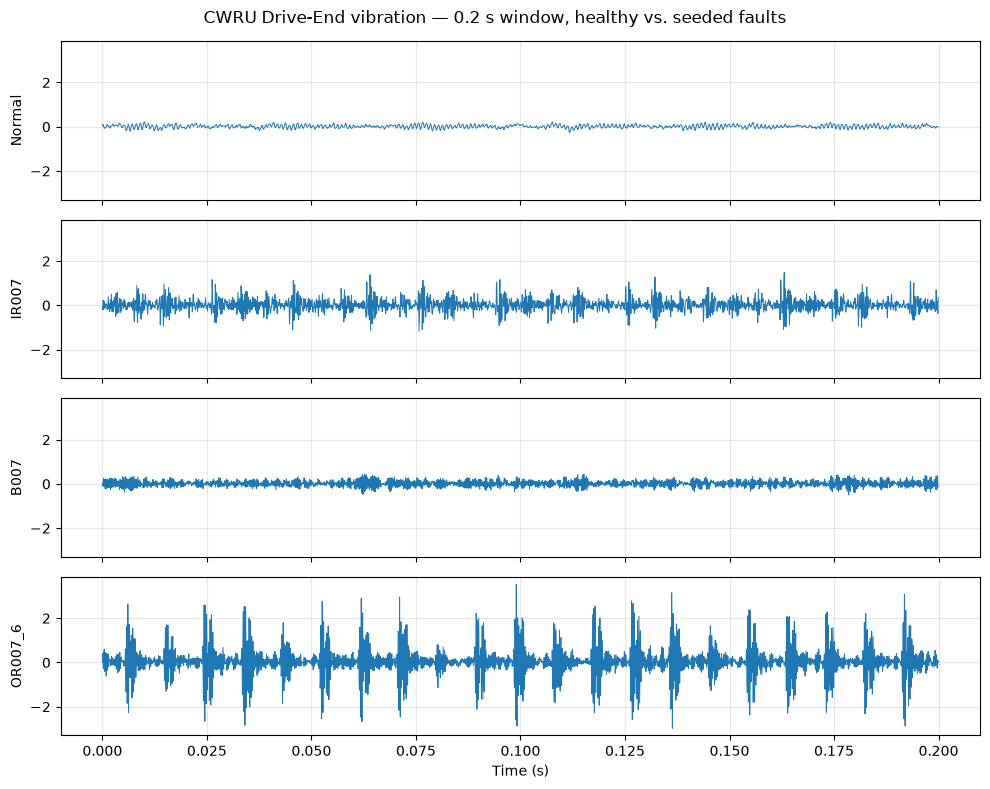

In [3]:
window = int(0.2 * SAMPLE_RATE_HZ)  # 0.2 seconds

fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True, sharey=True)
for ax, (label, sig) in zip(axes, signals.items()):
    t = np.arange(window) / SAMPLE_RATE_HZ
    ax.plot(t, sig[:window], linewidth=0.7)
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Time (s)")
fig.suptitle("CWRU Drive-End vibration — 0.2 s window, healthy vs. seeded faults")
plt.tight_layout()
plt.show()


## Turning raw signal into a feature/target table

This is the same idea as Paper 4's approach: don't feed raw waveforms to a
model — compute summary features per window, and label each row with the
known fault (`Status`), because *we* know which file each fault came from.

Features here: **RMS**, **Crest Factor** (peak / RMS), **Peak-to-Peak**.


In [4]:
def compute_features(sig, window_size=2048, label=None):
    """Chop a signal into non-overlapping windows and compute summary features."""
    n_windows = len(sig) // window_size
    rows = []
    for i in range(n_windows):
        w = sig[i * window_size : (i + 1) * window_size]
        rms = np.sqrt(np.mean(w ** 2))
        peak = np.max(np.abs(w))
        crest_factor = peak / rms if rms > 0 else np.nan
        peak_to_peak = w.max() - w.min()
        rows.append({
            "RMS": rms,
            "CrestFactor": crest_factor,
            "PeakToPeak": peak_to_peak,
            "Status": label,
        })
    return pd.DataFrame(rows)


feature_tables = [compute_features(sig, label=label) for label, sig in signals.items()]
dataset = pd.concat(feature_tables, ignore_index=True)
print(f"Total rows: {len(dataset)}  (features: RMS, CrestFactor, PeakToPeak | target: Status)")
dataset.sample(10, random_state=0)


Total rows: 296  (features: RMS, CrestFactor, PeakToPeak | target: Status)


,RMS,CrestFactor,PeakToPeak,Status
230,0.146110,3.636463,0.977697,B007
228,0.141420,3.495190,0.958530,B007
12,0.074849,2.918131,0.426618,Normal
215,0.144023,3.544810,0.987606,B007
264,0.647074,5.009938,6.261062,OR007_6
45,0.072167,3.642320,0.461040,Normal
238,0.688396,4.830137,6.407660,OR007_6
55,0.070797,3.326771,0.427453,Normal
213,0.130229,3.531128,0.900378,B007
63,0.074514,2.754872,0.408052,Normal


## Sanity check: do features separate the classes?

If the fault classes look visually distinct here, a simple classifier
(Random Forest, like Paper 4) should be able to separate them.


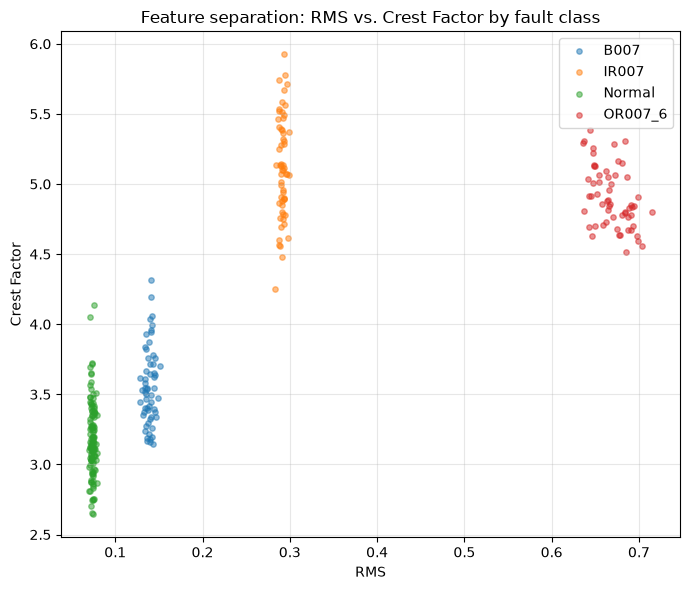

Status                  B007      IR007      Normal    OR007_6
RMS         count  59.000000  59.000000  119.000000  59.000000
            mean    0.139000   0.291431    0.073740   0.668894
            std     0.004817   0.003235    0.001964   0.019925
            min     0.128355   0.283143    0.070292   0.636378
            25%     0.135384   0.289843    0.072268   0.649475
            50%     0.139519   0.291143    0.073787   0.666537
            75%     0.142077   0.293390    0.074901   0.685421
            max     0.150725   0.299637    0.079491   0.714804
CrestFactor count  59.000000  59.000000  119.000000  59.000000
            mean    3.557936   5.119278    3.183082   4.903515
            std     0.275173   0.362978    0.265010   0.216037
            min     3.147741   4.251583    2.646803   4.517755
            25%     3.362887   4.870994    3.032375   4.747709
            50%     3.531128   5.102208    3.151146   4.858782
            75%     3.717873   5.385632    3.352265   5.055694
            max     4.314016   5.925084    4.139792   5.387261
PeakToPeak  count  59.000000  59.000000  119.000000  59.000000
            mean    0.944070   2.642957    0.443634   6.331708
            std     0.071431   0.139182    0.029037   0.208622
            min     0.828419   2.368304    0.379054   5.757107
            25%     0.875850   2.522536    0.425471   6.211519
            50%     0.934652   2.657926    0.444142   6.367457
            75%     0.993697   2.735164    0.460101   6.470806
            max     1.102447   2.997253    0.522373   6.756895

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
for label, group in dataset.groupby("Status"):
    ax.scatter(group["RMS"], group["CrestFactor"], label=label, alpha=0.5, s=15)
ax.set_xlabel("RMS")
ax.set_ylabel("Crest Factor")
ax.set_title("Feature separation: RMS vs. Crest Factor by fault class")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

dataset.groupby("Status")[["RMS", "CrestFactor", "PeakToPeak"]].describe().T
